# Урок 7 — Производная и градиент: куда двигать параметр

[План курса](../../README_ru.md) · [Предыдущий урок](lesson-06.ipynb) · [English](../en/lesson-07.ipynb) · [Следующий урок](lesson-08.ipynb)

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
from IPython.display import display

course_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "loss_demos.py").is_file()), None)
if course_root is None:
    raise FileNotFoundError("The notebook needs the complete course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from loss_demos import (
    image_errors, gaussian_image, bell, center_loss,
    central_difference, numerical_gradient, descent_steps,
    loss_figure, loss_lab, tiny_loss_figure, equal_loss_figure,
    descent_figure, descent_lab, rates_figure, gradient_figure,
)
LANG = 'ru'


Ошибка уже умеет оценивать картинку. Осталось понять, как по этому числу выбирать параметры. Начнём с одного: положения центра колокола. Ширина, высота и образец закреплены.

Немного сдвинем центр вправо и заново посчитаем ошибку. Если она уменьшилась, рядом с текущим положением есть полезное направление. Если увеличилась — вероятно, стоит двигаться в другую сторону. Это наблюдение можно записать числом: **насколько изменяется ошибка при маленьком изменении параметра**. Так мы подойдём к производной, а потом к градиенту.

## 1. Два графика с разными горизонтальными осями

Слева — яркость на прямой: горизонтальная ось $x$ обозначает место в изображении. Пунктир — образец с центром 1, сплошная линия — наше пятно. Справа — ошибка: горизонтальная ось обозначает возможный центр $\mu$. Каждая точка правого графика означает **целый левый график**, заново построенный при выбранном центре.

Оранжевая точка справа — текущее состояние, пустой кружок — следующее после одного обновления. Число шагов показывает, как постепенно меняются центр и ошибка. У обеих гауссиан масштаб 1 и высота 1. Сравниваются 81 значение на неподвижной сетке $x$ от −4 до 4 включительно. В начале наш центр −1, образец справа от него.

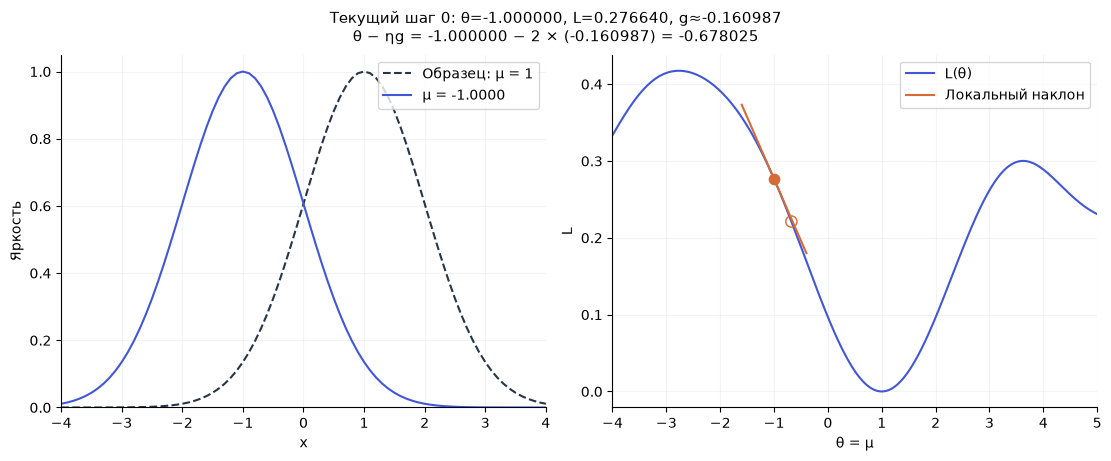

In [2]:
display(descent_figure(language=LANG))
display(descent_lab(language=LANG))

Оранжевая короткая прямая около текущей точки показывает местный наклон ошибки. Она не заменяет всю кривую: вдали от текущего центра её предсказание может быть неверным. Позже увидим, почему такой наклон плохо предсказывает результат слишком большого шага.

Параметр $h$ нужен для измерения наклона, $\eta$ — для обновления центра. Это разные настройки. Сначала разберём наклон на простом примере с точными числами, затем вернёмся к колоколу.

## 2. Простейшая ошибка: насколько число отличается от тройки

Пусть изменяемый параметр называется $\theta$ — «тета». В этом небольшом примере он должен приблизиться к 3. Ошибкой будет квадрат разности:

$$
L(\theta)=(\theta-3)^2.
$$

Скобки после $L$ обозначают вход функции: какое значение параметра оценивается. Внутри больших скобок сначала вычитаем 3, затем умножаем разность саму на себя. При $\theta=1$ получаем $(1-3)^2=(-2)^2=4$. При $\theta=2$ получаем 1, при 3 — 0, при 4 — снова 1. График — чаша с дном в 3.

theta = 0, loss = 9
theta = 1, loss = 4
theta = 2, loss = 1
theta = 3, loss = 0
theta = 4, loss = 1
theta = 5, loss = 4


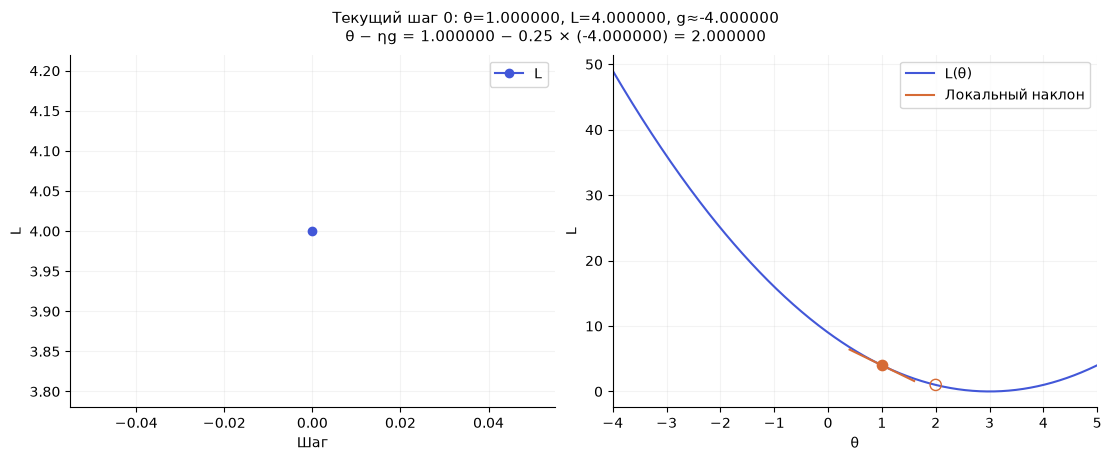

In [3]:
def toy_loss(theta):
    return (theta - 3) ** 2

for theta in [0, 1, 2, 3, 4, 5]:
    print(f"theta = {theta}, loss = {toy_loss(theta)}")
display(descent_figure(initial=1, rate=0.25, steps=0,
                       model="quadratic", language=LANG))

Здесь решение видно сразу: параметр должен равняться 3. Этот пример нужен не для поиска неизвестного ответа, а для проверки механизма, который затем будет работать с картинкой и многими параметрами.

## 3. Изменение ошибки делим на изменение параметра

Начнём в $\theta=1$ и сместимся вправо на $h=0.1$. Новая точка $1+0.1=1.1$. Новая ошибка $(1.1-3)^2=(-1.9)^2=3.61$.

Ошибка изменилась на $3.61-4=-0.39$. Делим на изменение параметра:

$$
\frac{L(1+0.1)-L(1)}{0.1}
=\frac{3.61-4}{0.1}
=\frac{-0.39}{0.1}=-3.9.
$$

Число −3.9 — **средний наклон** на маленьком отрезке. Минус говорит, что при движении вправо ошибка уменьшалась. Модуль говорит, как быстро: около 3.9 единицы ошибки на единицу параметра на этом отрезке.

Это не обещание уменьшить ошибку ровно на 3.9 после большого сдвига на 1. По дороге наклон меняется. Дробь измеряла конкретный короткий отрезок длиной 0.1.

Уменьшим $h$:

| h | Новая ошибка L(1+h) | Изменение ошибки | Изменение / h |
|---:|---:|---:|---:|
| 1 | 1 | −3 | −3 |
| 0.5 | 2.25 | −1.75 | −3.5 |
| 0.1 | 3.61 | −0.39 | −3.9 |
| 0.01 | 3.9601 | −0.0399 | −3.99 |
| 0.001 | 3.996001 | −0.003999 | −3.999 |

Наклон приближается к −4. Это и есть производная в точке 1.

## 4. Производная без пропуска самого перехода

Часто производную записывают так:

$$
L'(\theta)=\lim_{h\to0}\frac{L(\theta+h)-L(\theta)}{h}.
$$

Штрих в $L'$ означает производную, а не следующий момент времени. Запись $h\to0$ читается «аш стремится к нулю»: рассматриваем всё меньшие ненулевые смещения. $\lim$ — значение, к которому приближается дробь. **Подставлять $h=0$ в дробь нельзя**, иначе получится деление нуля на ноль.

В числителе разность двух ошибок. В знаменателе — смещение параметра. Вопрос такой: к какому наклону они приходят, когда отрезок около текущей точки становится совсем коротким? У некоторых функций такого единственного наклона нет; пример с модулем появится ниже.

Для нашей чаши можно раскрыть действия и получить точный ответ. Обозначим $d=\theta-3$, чтобы временно сократить запись. Тогда:

$$
\begin{aligned}
(d+h)^2&=(d+h)(d+h)\\
&=d^2+dh+hd+h^2\\
&=d^2+2dh+h^2.
\end{aligned}
$$

Каждый член первой скобки умножился на каждый член второй. Члены $dh$ и $hd$ одинаковы, поэтому вместе дают $2dh$. Теперь вычтем старую ошибку $d^2$:

$$
\frac{(d+h)^2-d^2}{h}
=\frac{2dh+h^2}{h}=2d+h,\qquad h\ne0.
$$

В обоих слагаемых числителя есть множитель $h$, его сокращение оставило $2d+h$. Когда $h$ приближается к нулю, остаётся $2d$. Возвращаем $d=\theta-3$:

$$
L'(\theta)=2(\theta-3).
$$

При 1 это $2(1-3)=-4$, при 2 — −2, при 3 — 0, при 4 — 2. Слева от дна выгодно двигаться вправо, справа — влево. В самом дне мгновенный наклон нулевой, хотя после конечного шага в любую сторону ошибка вырастет.

## 5. Численный наклон: две пробные картинки

Для сложной картинки пока не будем выводить производную всех операций. Ошибку уже умеет считать Python. Достаточно дважды вызвать эту функцию с чуть разными параметрами.

Более симметричная оценка берёт одну точку слева и одну справа:

$$
g_h(\theta)=\frac{L(\theta+h)-L(\theta-h)}{2h}.
$$

$g_h$ — оценка производной, полученная при конкретном $h$. Между двумя точками расстояние не $h$, а $2h$: от $\theta-h$ до $\theta$, затем ещё $h$ вправо. Поэтому в знаменателе $2h$. Знак порядка вычитания совпадает с движением слева направо.

Для чаши при $\theta=1$, $h=0.1$ слева ошибка $L(0.9)=(-2.1)^2=4.41$, справа $L(1.1)=3.61$. Получается $(3.61-4.41)/0.2=-0.8/0.2=-4$. В этом квадратном примере симметричная оценка точна при любом ненулевом $h$ в точной арифметике. Для произвольной кривой это приближение.

In [4]:
def slope(function, theta, h=0.01):
    right = function(theta + h)
    left = function(theta - h)
    return (right - left) / (2 * h)

for h in [0.5, 0.1, 0.01, 0.001]:
    print(f"h={h:g}, quadratic slope={slope(toy_loss, 1, h):.9f}")

h=0.5, quadratic slope=-4.000000000
h=0.1, quadratic slope=-4.000000000
h=0.01, quadratic slope=-4.000000000
h=0.001, quadratic slope=-4.000000000


Очень большое $h$ усредняет наклон слишком широкого участка. Очень маленькое заставляет вычитать почти одинаковые машинные числа: округление может съесть различие. Поэтому «меньше» не всегда «точнее». Для проверки обычно сравниваем несколько разумных $h$, а не верим одному выбранному числу.

## 6. Возвращаемся к положению гауссианы

Теперь $\theta$ — это центр $\mu$. Параметр изображения и координата пикселя — разные величины. Для каждого фиксированного $x_i$ вычисляется яркость нашего колокола:

$$
P_i(\mu)=\exp\left(-\frac{(x_i-\mu)^2}{2}\right).
$$

Это формула урока 2 с масштабом $\sigma=1$: знаменатель $2\sigma^2$ стал 2. Сначала вычитаем центр из координаты, возводим разность в квадрат, делим на 2, ставим минус и вычисляем экспоненту. Высота 1 и масштаб 1 закреплены. Образец $T_i$ вычисляется тем же способом, но с центром 1.

Сравниваем 81 значение:

$$
L(\mu)=\frac1{81}\sum_{i=1}^{81}\bigl(P_i(\mu)-T_i\bigr)^2.
$$

Сначала при данном центре строится вся кривая, затем вычитается образец, затем считаются квадраты и среднее. При смещении центра перестраиваются **все** $P_i$, а не только один пиксель.

In [5]:
x = np.linspace(-4, 4, 81)
target = np.exp(-0.5 * (x - 1.0) ** 2)

def image_loss(mu):
    prediction = np.exp(-0.5 * (x - mu) ** 2)
    return np.mean((prediction - target) ** 2)

mu, h = -1.0, 0.01
left, right = image_loss(mu - h), image_loss(mu + h)
gradient = (right - left) / (2 * h)
print(f"L({mu-h:.2f}) = {left:.9f}")
print(f"L({mu+h:.2f}) = {right:.9f}")
print(f"gradient ≈ {gradient:.9f}")

L(-1.01) = 0.278245476
L(-0.99) = 0.275025729
gradient ≈ -0.160987390


Получаются $L(-1.01)\approx0.278245476$, $L(-0.99)\approx0.275025729$. Вычитание даёт примерно −0.003219748; деление на 0.02 — примерно −0.160987390. Наклон отрицательный: маленькое увеличение центра уменьшает ошибку. Число не является координатой нового центра; это пока только наклон.

## 7. Один шаг вниз по ошибке

Обновление параметра запишем так:

$$
\theta_{\mathrm{new}}=\theta_{\mathrm{old}}-\eta g.
$$

`old` и `new` — подписи старого и нового значения. $g$ — производная или её оценка в **старой** точке. $\eta$, «эта», — положительный размер шага, learning rate. Он переводит величину наклона в величину перемещения. Произведение $\eta g$ вычисляется до вычитания.

Если $g$ положителен, вычитание двигает параметр влево. Если отрицателен, вычитается отрицательное число и параметр увеличивается. В обоих случаях идём против направления роста ошибки. Это и называется градиентным спуском; пока у него всего один параметр.

Для чаши при $\theta=1$, $g=-4$, $\eta=0.25$:

$$
\theta_{\mathrm{new}}=1-0.25\cdot(-4)=1-(-1)=2.
$$

Ошибка была 4, стала $(2-3)^2=1$. Дальше производная уже −2, а не −4. Поэтому следующий шаг будет $2-0.25(-2)=2.5$. Наклон нужно пересчитывать после каждого обновления.

Для нашего колокола при центре −1 и $\eta=2$:

$$
\mu_{\mathrm{new}}=-1-2\cdot(-0.160987390)
\approx-1+0.321974781=-0.678025219.
$$

Ошибка уменьшается с 0.276639631 примерно до 0.221169006. Здесь значение $\eta$ совсем другое, потому что шкала наклона другой функции тоже другая. Универсального удачного числа для всех задач нет.

In [6]:
mu, rate = -1.0, 2.0
for step in range(6):
    loss = image_loss(mu)
    print(f"step {step}: mu={mu:.6f}, MSE={loss:.9f}")
    if step < 5:
        gradient = slope(image_loss, mu, h=0.01)
        mu = mu - rate * gradient

step 0: mu=-1.000000, MSE=0.276639631
step 1: mu=-0.678025, MSE=0.221169006
step 2: mu=-0.314787, MSE=0.153566610
step 3: mu=0.058703, MSE=0.086954529
step 4: mu=0.388796, MSE=0.039020754
step 5: mu=0.632426, MSE=0.014534806


$h$ в этом коде равен 0.01, но фактическое первое перемещение центра около 0.322. $h$ — расстояние для двух измерений, $\eta g$ — величина обучения. Подменять одно другим нельзя.

## 8. Маленький, большой и слишком большой шаг

У простой чаши легко проверить разные скорости. Из точки 1:

| η | Новый параметр | Новая ошибка | Что произошло |
|---:|---:|---:|---|
| 0.1 | 1 − 0.1(−4) = 1.4 | 2.56 | Медленное приближение |
| 0.5 | 1 − 0.5(−4) = 3 | 0 | Попадание в дно за шаг |
| 0.9 | 1 − 0.9(−4) = 4.6 | 2.56 | Перелёт, но ошибка уменьшилась |
| 1 | 1 − 1(−4) = 5 | 4 | Движение между 1 и 5 |
| 1.1 | 1 − 1.1(−4) = 5.4 | 5.76 | Перелёт с ростом ошибки |

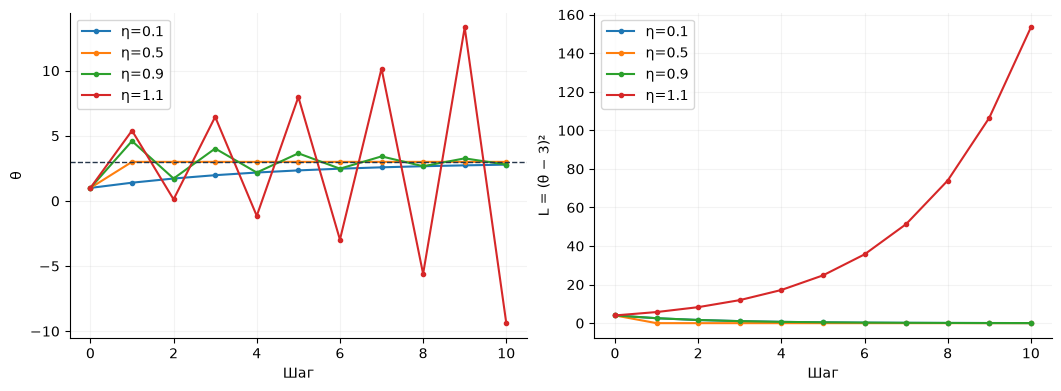

In [7]:
display(rates_figure(language=LANG))

При $\eta=0.9$ шаги прыгают через дно, но амплитуда уменьшается. При 1.1 она растёт. Производная не ошиблась в направлении: большой шаг просто ушёл за область, где местный наклон был полезным предсказанием.

Эти конкретные границы относятся к $L=(\theta-3)^2$. Если умножить loss на 100, производная тоже станет в 100 раз больше и прежний размер шага перестанет означать прежнее перемещение. В сложной задаче график ошибки и величина реальных обновлений помогают выбрать шаг лучше, чем одно «обычное» значение.

## 9. Несколько параметров: каждый меняется отдельно

Теперь пятно умеет менять и центр $\mu$, и высоту $a$. Ошибка зависит от двух чисел: $L(\mu,a)$. Чтобы измерить влияние центра, слегка меняем **только центр**, оставляя высоту прежней. Затем возвращаем центр и измеряем влияние высоты. Две производные складываем в список:

$$
\nabla L=
\begin{bmatrix}
\partial L/\partial\mu\\
\partial L/\partial a
\end{bmatrix}
=\begin{bmatrix}g_\mu\\g_a\end{bmatrix}.
$$

Знак $\nabla$, «набла», обозначает **градиент** — набор производных по каждому параметру. Круглый знак $\partial$ читается как знак частной производной: изменяется один выбранный параметр, остальные зафиксированы. Это не деление loss на центр. Вектор здесь — столбец двух чисел в том же порядке, что и параметры.

Для совсем прозрачной арифметики возьмём временную ошибку:

$$
Q(\mu,a)=(\mu-1)^2+4(a-0.5)^2.
$$

Первое слагаемое сравнивает центр с 1, второе — высоту с 0.5. Четвёрка делает вклад второй разности в четыре раза сильнее. По уже разобранному правилу квадрата $g_\mu=2(\mu-1)$ и $g_a=4\cdot2(a-0.5)=8(a-0.5)$. При $(\mu,a)=(0,1)$ получаем $(-2,4)$.

Шаг с $\eta=0.1$ обновляет оба числа из **одного старого состояния**:

$$
\mu_{\mathrm{new}}=0-0.1(-2)=0.2,\qquad
a_{\mathrm{new}}=1-0.1\cdot4=0.6.
$$

Старая ошибка $1+4\cdot0.25=2$. Новая $(-0.8)^2+4(0.1)^2=0.64+0.04=0.68$. Вот и вся операция над вектором: два обычных умножения и два вычитания.

Для реального колокола вычислим обе производные численно:

gradient: [-0.0965959   0.10158385]
updated: [-0.8068082   0.39683231]
loss before / after: 0.20099493558592782 0.17649271711783351


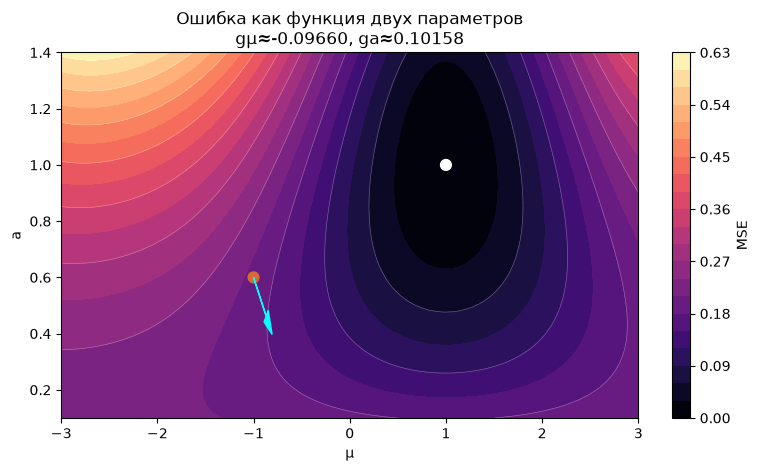

In [8]:
parameters = np.array([-1.0, 0.6])  # center, height

def two_parameter_loss(values):
    mu, gain = values
    prediction = gain * np.exp(-0.5 * (x - mu) ** 2)
    return np.mean((prediction - target) ** 2)

gradient = numerical_gradient(two_parameter_loss, parameters, h=0.001)
updated = parameters - 2.0 * gradient
print("gradient:", gradient)
print("updated:", updated)
print("loss before / after:", two_parameter_loss(parameters), two_parameter_loss(updated))
display(gradient_figure(language=LANG))

На карте горизонтальная ось — центр, вертикальная — высота. Цвет показывает MSE для каждой пары параметров: тёмное означает меньшую ошибку. Оранжевая точка — исходная пара (−1, 0.6), белая — точное совпадение (1, 1). Голубая стрелка показывает один шаг с коэффициентом 2 против градиента. Здесь для обзора формы ошибки высота на карте продолжается до 1.4. Это математическое продолжение функции без обрезания значений, а не ограниченная шкала отображения яркости. В проекте допустимый диапазон цвета будет задан отдельно.

При центре −1 и высоте 0.6 получаются приблизительно $g_\mu=-0.096596$ и $g_a=0.101584$. Центр двигается вправо, высота уменьшается. Хотя у образца высота 1! Пока пятно стоит не там, ослабить его тоже выгодно: исчезает часть ошибочной яркости. Градиент отвечает на местный вопрос об общей ошибке, а не отдельно узнаёт «правильное значение» каждого параметра.

Численные величины двух компонент зависят от единиц параметров. Перевод координаты из метров в сантиметры изменит её производную. Сравнивать модули и выбирать одинаковый шаг для центра, цвета и размера без учёта их шкал бывает неудобно. В проекте параметры будут иметь явные диапазоны, а способ обновления получит отдельные настройки.

## 10. Нулевой наклон не всегда означает решение

У нашей чаши нулевая производная находится в самом дне. Но у функции $-(\theta-3)^2$ в той же точке был бы **максимум**. Бывают и почти плоские участки далеко от хорошего решения. Одного маленького градиента недостаточно — рядом остаются ошибка и картинка.

У колокола появляется ещё проблема границ кадра. Если начальный центр поставить в 4, большая часть пятна находится у правого края. Местный наклон ошибки отрицателен: маленький сдвиг **ещё правее** снижает MSE, хотя образец находится в 1. Программа убирает неверное пятно из видимой области вместо того, чтобы сразу перенести его на образец. За кадром остаётся ненулевая ошибка от пропущенного образца, но изменять её центром почти невозможно.

In [9]:
for mu in [1.0, 4.0, 4.1, 8.0]:
    print(f"mu={mu:g}: MSE={image_loss(mu):.6f}, slope≈{slope(image_loss, mu):.6f}")

mu=1: MSE=0.000000, slope≈-0.000000
mu=4: MSE=0.288928, slope≈-0.053858
mu=4.1: MSE=0.283123, slope≈-0.061723
mu=8: MSE=0.218819, slope≈0.000002


Это не ошибка знака в коде. Производная локально верна, но вся задача не обязана быть одной удобной чашей. Начальные положения, размеры пятен и покрытие изображения влияют на обучение. Мы вернёмся к ним в проекте.

Есть и функция без производной в отдельной точке: $|\theta|$ имеет наклон −1 слева от нуля и +1 справа. В нуле они не сходятся к одному числу. Симметричная разность даст 0, но это не доказывает существование производной. Библиотеки выбирают соглашения для таких мест. Здесь мы начали с гладкой MSE и гладкой гауссианы, чтобы сначала понять основной механизм.

## 11. Опыты с предсказанием

**Другой знак.** У чаши $L=(\theta-3)^2$ старый параметр 5, размер шага 0.25. Куда он попадёт и чему будет равна ошибка?

<details>
<summary>Разбор</summary>

Производная $2(5-3)=4$, положительная. Обновление $5-0.25\cdot4=4$. Ошибка была 4, стала 1. Положительный наклон приводит к уменьшению параметра, а не к увеличению.

</details>

**Изменилось измерение, а не обучение.** В опыте с колоколом $h$ уменьшается с 0.1 до 0.01 при неизменном $\eta=2$. Уменьшится ли шаг обучения в десять раз?

<details>
<summary>Разбор</summary>

Нет. При центре −1 оценки наклона примерно −0.160854 и −0.160987. В обоих случаях фактический шаг близок к $2\cdot0.161=0.322$. Меняется точность измерения, а не заданный коэффициент обучения.

</details>

**Два обновления одновременно.** Для функции $Q$ выше из точки $(0,1)$ берётся шаг 0.25. Что получится?

<details>
<summary>Разбор</summary>

Старый градиент $(-2,4)$. Новая пара $(0-0.25(-2),\ 1-0.25\cdot4)=(0.5,0)$. Ошибка $(-0.5)^2+4(-0.5)^2=0.25+1=1.25$, меньше исходных 2. Но высота перескочила через 0.5. При повторении с тем же шагом её ошибка будет колебаться: один размер шага может вести себя по-разному по разным направлениям.

</details>

**Неподвижное пятно за кадром.** Почти нулевой наклон при центре 8 не сопровождается нулевой MSE. Это признак точного восстановления?

<details>
<summary>Разбор</summary>

Нет. На видимой сетке наша гауссиана почти исчезла; образец всё ещё отсутствует. Небольшое перемещение далёкого центра почти не меняет наблюдаемые пиксели, поэтому производная мала. Хороший критерий остановки должен учитывать не только градиент, но и сам результат.

</details>

Численная разность дала рабочий спуск, но за каждую компоненту градиента пришлось дважды строить изображение. Для тысячи параметров это уже две тысячи рендеров на один шаг. В [следующем уроке](lesson-08.ipynb) разберём, как получить производные через цепочку самих вычислений, и проверим результат автоматического дифференцирования теми же маленькими сдвигами.